# Cosmología unimodular con difusión de potencia  
## Solución temporal, validaciones y clasificación abierta

Se estudia el modelo

\[
p=\omega\rho,
\qquad
Q=\alpha\rho^\beta,
\]

con

\[
3H^2=\rho+Q=\rho+\alpha\rho^\beta,
\]

\[
\dot H=-\frac{1+\omega}{2}\rho,
\]

\[
\left(1+\alpha\beta\rho^{\beta-1}\right)\dot\rho
+3H(1+\omega)\rho=0.
\]

El notebook tiene cuatro objetivos:

1. implementar una solución temporal numérica autocontenida;
2. validar el algoritmo mediante soluciones exactas e identidades internas;
3. estudiar todas las ramas físicas relevantes del espacio de parámetros;
4. clasificar los comportamientos **a partir de lo observado**, sin imponer que deban coincidir con categorías esperadas.

La clasificación final conserva etiquetas abiertas para detectar comportamientos no estándar. En particular, se permiten:

- expansión regular;
- de Sitter exacto o asintótico;
- Big Rip en tiempo finito;
- divergencia en tiempo infinito;
- rip dominado por difusión;
- frontera de derivadas superiores;
- turnaround y contracción;
- Big Crunch;
- comportamiento no concluyente.

> Las pruebas con resultados esperados se usan únicamente para validar el código —por ejemplo, una identidad algebraica exacta—. Las conclusiones físicas se obtienen de límites, convergencia de umbrales, continuación con \(H\) signado y consistencia entre diagnósticos independientes.

## 1. Importaciones y configuración

El notebook es autocontenido y no depende de `src/models.py`.

In [1]:
from dataclasses import dataclass, asdict
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.integrate import solve_ivp, quad

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

RHO0 = 1.0
A0 = 1.0
T0 = 0.0

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.3.3
Pandas: 2.2.3


## 2. Estructura matemática

Definimos

\[
F(\rho)=1+\alpha\rho^{\beta-1},
\qquad
D(\rho)=1+\alpha\beta\rho^{\beta-1}.
\]

La rama expansiva requiere

\[
F(\rho)>0,
\]

mientras que la ecuación de evolución escrita en términos de \(\rho\) es regular si

\[
D(\rho)\neq0.
\]

La relación integrada entre densidad y factor de escala es

\[
\ln\left(\frac{\rho}{\rho_0}\right)
+
\frac{\alpha\beta}{\beta-1}
\left(
\rho^{\beta-1}-\rho_0^{\beta-1}
\right)
=
-3(1+\omega)
\ln\left(\frac{a}{a_0}\right),
\qquad \beta\neq1.
\]

Para \(\beta=1\),

\[
(1+\alpha)\ln\left(\frac{\rho}{\rho_0}\right)
=
-3(1+\omega)\ln\left(\frac{a}{a_0}\right).
\]

In [2]:
@dataclass(frozen=True)
class CosmologyParams:
    omega: float
    alpha: float
    beta: float
    rho0: float = 1.0
    a0: float = 1.0
    t0: float = 0.0

    def validate(self):
        values = [
            self.omega,
            self.alpha,
            self.beta,
            self.rho0,
            self.a0,
            self.t0,
        ]

        if not all(np.isfinite(values)):
            raise ValueError("Todos los parámetros deben ser finitos.")

        if self.rho0 <= 0.0:
            raise ValueError("rho0 debe ser positiva.")

        if self.a0 <= 0.0:
            raise ValueError("a0 debe ser positivo.")

In [3]:
class BarotropicDiffusionModel:
    """Modelo p = omega*rho y Q = alpha*rho**beta."""

    def __init__(self, params):
        params.validate()
        self.params = params

    def F(self, rho):
        rho = np.asarray(rho, dtype=float)
        return (
            1.0
            + self.params.alpha
            * rho ** (self.params.beta - 1.0)
        )

    def D(self, rho):
        rho = np.asarray(rho, dtype=float)
        return (
            1.0
            + self.params.alpha
            * self.params.beta
            * rho ** (self.params.beta - 1.0)
        )

    def hubble(self, rho, branch=1.0):
        rho = np.asarray(rho, dtype=float)

        radicand = rho * self.F(rho) / 3.0

        if np.any(radicand < -1e-13):
            raise ValueError(
                "Se intentó evaluar H fuera del dominio H^2 >= 0."
            )

        return (
            float(branch)
            * np.sqrt(np.maximum(radicand, 0.0))
        )

    def hdot(self, rho):
        rho = np.asarray(rho, dtype=float)

        return (
            -0.5
            * (1.0 + self.params.omega)
            * rho
        )

    def rho_dot(self, rho, H=None):
        rho = np.asarray(rho, dtype=float)

        if H is None:
            H = self.hubble(rho)

        return (
            -3.0
            * np.asarray(H, dtype=float)
            * (1.0 + self.params.omega)
            * rho
            / self.D(rho)
        )

    def log_a_of_rho(self, rho):
        """Retorna ln(a) usando la relación integrada rho(a)."""

        params = self.params
        rho = np.asarray(rho, dtype=float)

        if np.isclose(1.0 + params.omega, 0.0):
            return np.full_like(
                rho,
                np.log(params.a0),
                dtype=float,
            )

        if np.isclose(params.beta, 1.0):
            conservation_term = (
                (1.0 + params.alpha)
                * np.log(rho / params.rho0)
            )
        else:
            conservation_term = (
                np.log(rho / params.rho0)
                + (
                    params.alpha
                    * params.beta
                    / (params.beta - 1.0)
                )
                * (
                    rho ** (params.beta - 1.0)
                    - params.rho0 ** (params.beta - 1.0)
                )
            )

        return (
            np.log(params.a0)
            - conservation_term
            / (3.0 * (1.0 + params.omega))
        )

## 3. Solucionador de la rama expansiva

Para mantener \(\rho>0\) y \(a>0\), integramos

\[
x=\ln\rho,
\qquad
N=\ln a.
\]

Entonces

\[
\dot x=
-\frac{3H(1+\omega)}{D(\rho)},
\qquad
\dot N=H.
\]

Este primer solucionador utiliza

\[
H=+\sqrt{\frac{\rho F(\rho)}{3}},
\]

por lo que sigue exclusivamente la rama expansiva. Se detiene en umbrales numéricos o al aproximarse a \(F=0\) o \(D=0\).

In [4]:
def solve_expanding_background(
    model,
    t_end,
    n_points=1200,
    *,
    rho_min=1e-14,
    rho_max=1e12,
    a_max=1e80,
    boundary_tol=1e-8,
    method="DOP853",
    rtol=1e-9,
    atol=1e-11,
    max_step=np.inf,
):
    params = model.params

    if t_end <= params.t0:
        raise ValueError("t_end debe ser mayor que t0.")

    if n_points < 2:
        raise ValueError("n_points debe ser al menos 2.")

    F0 = float(model.F(params.rho0))
    D0 = float(model.D(params.rho0))

    if F0 <= boundary_tol:
        raise ValueError(
            f"Condición inicial fuera del dominio: F0={F0:.6e}."
        )

    if abs(D0) <= boundary_tol:
        raise ValueError(
            f"Condición inicial en la frontera D=0: D0={D0:.6e}."
        )

    sign_D0 = float(np.sign(D0))

    y0 = np.array(
        [
            np.log(params.rho0),
            np.log(params.a0),
        ],
        dtype=float,
    )

    def rhs(t, y):
        rho = np.exp(y[0])
        F = float(model.F(rho))
        D = float(model.D(rho))
        H = np.sqrt(max(rho * F / 3.0, 0.0))

        return np.array(
            [
                -3.0
                * H
                * (1.0 + params.omega)
                / D,
                H,
            ]
        )

    log_rho_min = np.log(rho_min)
    log_rho_max = np.log(rho_max)
    log_a_max = np.log(a_max)

    def event_rho_min(t, y):
        return y[0] - log_rho_min

    def event_rho_max(t, y):
        return log_rho_max - y[0]

    def event_a_max(t, y):
        return log_a_max - y[1]

    def event_F_boundary(t, y):
        rho = np.exp(y[0])
        return float(model.F(rho)) - boundary_tol

    def event_D_boundary(t, y):
        rho = np.exp(y[0])
        return (
            sign_D0 * float(model.D(rho))
            - boundary_tol
        )

    events = [
        event_rho_min,
        event_rho_max,
        event_a_max,
        event_F_boundary,
        event_D_boundary,
    ]

    for event in events:
        event.terminal = True
        event.direction = -1

    solution = solve_ivp(
        rhs,
        (params.t0, t_end),
        y0,
        method=method,
        dense_output=True,
        events=events,
        rtol=rtol,
        atol=atol,
        max_step=max_step,
    )

    event_names = [
        "rho_min",
        "rho_max",
        "a_max",
        "F_boundary",
        "D_boundary",
    ]

    termination_event = None
    termination_time = None

    for event_name, event_times in zip(
        event_names,
        solution.t_events,
    ):
        if len(event_times) > 0:
            candidate_time = float(event_times[0])

            if (
                termination_time is None
                or candidate_time < termination_time
            ):
                termination_event = event_name
                termination_time = candidate_time

    if termination_time is None:
        termination_time = float(solution.t[-1])

    t_grid = np.linspace(
        params.t0,
        termination_time,
        n_points,
    )

    y_grid = solution.sol(t_grid)

    rho = np.exp(y_grid[0])
    a = np.exp(y_grid[1])
    H = model.hubble(rho)
    Hdot = model.hdot(rho)

    result = pd.DataFrame(
        {
            "t": t_grid,
            "rho": rho,
            "a": a,
            "H": H,
            "Hdot": Hdot,
        }
    )

    result.attrs.update(
        {
            "solver_success": bool(solution.success),
            "solver_message": solution.message,
            "termination_event": termination_event,
            "termination_time": termination_time,
            "requested_t_end": t_end,
            "reached_t_end": (
                termination_event is None
                and np.isclose(termination_time, t_end)
            ),
            "boundary_tol": boundary_tol,
        }
    )

    return result

## 4. Solucionador con \(H\) signado

Una frontera \(F(\rho)=0\) implica \(H=0\), pero no necesariamente una singularidad. Para comprobar si la solución continúa hacia contracción, integramos

\[
(x,N,H)=(\ln\rho,\ln a,H)
\]

con

\[
\dot x=
-\frac{3H(1+\omega)}{D(\rho)},
\qquad
\dot N=H,
\qquad
\dot H=-\frac{1+\omega}{2}\rho.
\]

Este sistema permite que \(H\) cambie de signo. También controla la restricción

\[
3H^2-\rho F(\rho)=0.
\]

In [5]:
def solve_signed_background(
    model,
    t_end,
    n_points=1600,
    *,
    rho_min=1e-14,
    rho_max=1e12,
    a_min=1e-16,
    a_max=1e80,
    boundary_tol=1e-8,
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
    max_step=0.01,
):
    params = model.params

    F0 = float(model.F(params.rho0))
    D0 = float(model.D(params.rho0))

    if F0 <= 0.0:
        raise ValueError(
            f"El estado inicial no satisface F0>0: F0={F0:.6e}."
        )

    if abs(D0) <= boundary_tol:
        raise ValueError(
            f"El estado inicial está demasiado cerca de D=0: D0={D0:.6e}."
        )

    H0 = float(model.hubble(params.rho0))
    sign_D0 = float(np.sign(D0))

    y0 = np.array(
        [
            np.log(params.rho0),
            np.log(params.a0),
            H0,
        ],
        dtype=float,
    )

    def rhs(t, y):
        rho = np.exp(y[0])
        H = y[2]
        D = float(model.D(rho))

        return np.array(
            [
                -3.0
                * H
                * (1.0 + params.omega)
                / D,
                H,
                -0.5
                * (1.0 + params.omega)
                * rho,
            ]
        )

    log_rho_min = np.log(rho_min)
    log_rho_max = np.log(rho_max)
    log_a_min = np.log(a_min)
    log_a_max = np.log(a_max)

    def event_rho_min(t, y):
        return y[0] - log_rho_min

    def event_rho_max(t, y):
        return log_rho_max - y[0]

    def event_a_min(t, y):
        return y[1] - log_a_min

    def event_a_max(t, y):
        return log_a_max - y[1]

    def event_D_boundary(t, y):
        rho = np.exp(y[0])
        return (
            sign_D0 * float(model.D(rho))
            - boundary_tol
        )

    def event_H_zero(t, y):
        return y[2]

    terminal_events = [
        event_rho_min,
        event_rho_max,
        event_a_min,
        event_a_max,
        event_D_boundary,
    ]

    for event in terminal_events:
        event.terminal = True
        event.direction = -1

    event_H_zero.terminal = False
    event_H_zero.direction = -1

    events = terminal_events + [event_H_zero]

    solution = solve_ivp(
        rhs,
        (params.t0, t_end),
        y0,
        method=method,
        dense_output=True,
        events=events,
        rtol=rtol,
        atol=atol,
        max_step=max_step,
    )

    event_names = [
        "rho_min",
        "rho_max",
        "a_min",
        "a_max",
        "D_boundary",
    ]

    termination_event = None
    termination_time = None

    for event_name, event_times in zip(
        event_names,
        solution.t_events[:5],
    ):
        if len(event_times) > 0:
            candidate_time = float(event_times[0])

            if (
                termination_time is None
                or candidate_time < termination_time
            ):
                termination_event = event_name
                termination_time = candidate_time

    if termination_time is None:
        termination_time = float(solution.t[-1])

    t_grid = np.linspace(
        params.t0,
        termination_time,
        n_points,
    )

    y_grid = solution.sol(t_grid)

    rho = np.exp(y_grid[0])
    a = np.exp(y_grid[1])
    H = y_grid[2]
    Hdot = model.hdot(rho)

    constraint_left = 3.0 * H**2
    constraint_right = rho * model.F(rho)

    constraint_residual = (
        constraint_left - constraint_right
    ) / np.maximum(
        np.abs(constraint_left)
        + np.abs(constraint_right),
        1e-300,
    )

    result = pd.DataFrame(
        {
            "t": t_grid,
            "rho": rho,
            "a": a,
            "H": H,
            "Hdot": Hdot,
            "constraint_residual": constraint_residual,
        }
    )

    result.attrs.update(
        {
            "solver_success": bool(solution.success),
            "solver_message": solution.message,
            "termination_event": termination_event,
            "termination_time": termination_time,
            "H_zero_times": [
                float(value)
                for value in solution.t_events[5]
            ],
            "boundary_tol": boundary_tol,
        }
    )

    return result

## 5. Densidades críticas y dominio

Para \(\beta\neq1\), cuando existen:

\[
\rho_H=
\left(-\frac{1}{\alpha}\right)^{1/(\beta-1)},
\qquad F(\rho_H)=0,
\]

\[
\rho_D=
\left(-\frac{1}{\alpha\beta}\right)^{1/(\beta-1)},
\qquad D(\rho_D)=0.
\]

In [6]:
def critical_density_summary(params):
    if np.isclose(params.beta, 1.0):
        return {
            "rho_H": np.nan,
            "rho_D": np.nan,
        }

    rho_H = np.nan
    rho_D = np.nan

    if params.alpha < 0.0:
        rho_H = (
            -1.0 / params.alpha
        ) ** (
            1.0 / (params.beta - 1.0)
        )

    if params.alpha * params.beta < 0.0:
        rho_D = (
            -1.0
            / (
                params.alpha
                * params.beta
            )
        ) ** (
            1.0 / (params.beta - 1.0)
        )

    return {
        "rho_H": float(rho_H)
        if np.isfinite(rho_H)
        else np.nan,
        "rho_D": float(rho_D)
        if np.isfinite(rho_D)
        else np.nan,
    }


def initial_domain_summary(case_id, params):
    model = BarotropicDiffusionModel(params)

    F0 = float(model.F(params.rho0))
    D0 = float(model.D(params.rho0))

    critical = critical_density_summary(params)

    if np.isclose(1.0 + params.omega, 0.0):
        rho_direction = "constante"
    else:
        rho_dot0 = float(
            model.rho_dot(
                params.rho0,
                model.hubble(params.rho0),
            )
        )

        if rho_dot0 > 0.0:
            rho_direction = "creciente"
        elif rho_dot0 < 0.0:
            rho_direction = "decreciente"
        else:
            rho_direction = "estacionaria"

    return {
        "case_id": case_id,
        **asdict(params),
        "F0": F0,
        "D0": D0,
        "physical_initial_state": F0 > 0.0,
        "regular_initial_state": (
            F0 > 0.0
            and not np.isclose(D0, 0.0)
        ),
        "initial_rho_direction": rho_direction,
        **critical,
    }

## 6. Validación del solucionador

Las validaciones no clasifican la física. Solo comprueban que el código reproduce:

- condiciones iniciales;
- la solución exacta para \(\beta=1\);
- la relación integrada \(\rho(a)\);
- las ecuaciones de Friedmann, Raychaudhuri y continuidad;
- los eventos numéricos;
- la restricción del solucionador con \(H\) signado.

### 6.1 Caso exacto \(\beta=1\)

Para \(\beta=1\),

\[
H_0=\sqrt{\frac{(1+\alpha)\rho_0}{3}},
\]

\[
B(t)=
1+
\frac{3(1+\omega)H_0}{2(1+\alpha)}
(t-t_0),
\]

\[
\rho(t)=\rho_0B^{-2},
\qquad
a(t)=a_0
B^{2(1+\alpha)/[3(1+\omega)]},
\qquad
H(t)=H_0B^{-1}.
\]

In [7]:
validation_params = CosmologyParams(
    omega=-1.2,
    alpha=0.3,
    beta=1.0,
)

validation_model = BarotropicDiffusionModel(
    validation_params
)

validation_background = solve_expanding_background(
    validation_model,
    t_end=2.0,
    n_points=2000,
    rho_max=1e12,
    a_max=1e12,
)

t = validation_background["t"].to_numpy()

H0 = np.sqrt(
    (1.0 + validation_params.alpha)
    * validation_params.rho0
    / 3.0
)

B = (
    1.0
    + (
        3.0
        * (1.0 + validation_params.omega)
        * H0
        / (
            2.0
            * (1.0 + validation_params.alpha)
        )
    )
    * (t - validation_params.t0)
)

rho_exact = (
    validation_params.rho0
    * B ** (-2.0)
)

a_exact = (
    validation_params.a0
    * B ** (
        2.0
        * (1.0 + validation_params.alpha)
        / (
            3.0
            * (1.0 + validation_params.omega)
        )
    )
)

H_exact = H0 / B

Hdot_exact = (
    -0.5
    * (1.0 + validation_params.omega)
    * rho_exact
)


def maximum_relative_error(numerical, exact):
    numerical = np.asarray(numerical, dtype=float)
    exact = np.asarray(exact, dtype=float)

    return float(
        np.max(
            np.abs(numerical - exact)
            / np.maximum(
                np.abs(exact),
                1e-300,
            )
        )
    )


beta_one_validation = pd.DataFrame(
    {
        "variable": [
            "rho",
            "a",
            "H",
            "Hdot",
        ],
        "maximum_relative_error": [
            maximum_relative_error(
                validation_background["rho"],
                rho_exact,
            ),
            maximum_relative_error(
                validation_background["a"],
                a_exact,
            ),
            maximum_relative_error(
                validation_background["H"],
                H_exact,
            ),
            maximum_relative_error(
                validation_background["Hdot"],
                Hdot_exact,
            ),
        ],
    }
)

beta_one_validation["passes_1e-7"] = (
    beta_one_validation[
        "maximum_relative_error"
    ]
    < 1e-7
)

beta_one_validation

,variable,maximum_relative_error,passes_1e-7
0,rho,7.332887e-10,True
1,a,1.588791e-09,True
2,H,3.666444e-10,True
3,Hdot,7.332887e-10,True


### 6.2 Validación general para \(\beta\neq1\)

In [8]:
general_validation_params = CosmologyParams(
    omega=-1.2,
    alpha=0.3,
    beta=1.5,
)

general_validation_model = BarotropicDiffusionModel(
    general_validation_params
)

general_background = solve_expanding_background(
    general_validation_model,
    t_end=1.0,
    n_points=4000,
    max_step=0.005,
)

rho = general_background["rho"].to_numpy()
a = general_background["a"].to_numpy()
H = general_background["H"].to_numpy()
Hdot = general_background["Hdot"].to_numpy()
t = general_background["t"].to_numpy()

params = general_validation_params

integrated_residual = (
    np.log(rho / params.rho0)
    + (
        params.alpha
        * params.beta
        / (params.beta - 1.0)
    )
    * (
        rho ** (params.beta - 1.0)
        - params.rho0 ** (params.beta - 1.0)
    )
    + 3.0
    * (1.0 + params.omega)
    * np.log(a / params.a0)
)

friedmann_residual = (
    3.0 * H**2
    - (
        rho
        + params.alpha * rho**params.beta
    )
)

hdot_residual = (
    Hdot
    + 0.5
    * (1.0 + params.omega)
    * rho
)

rho_dot_numerical = np.gradient(
    rho,
    t,
    edge_order=2,
)

rho_dot_equation = (
    general_validation_model.rho_dot(
        rho,
        H,
    )
)

a_dot_numerical = np.gradient(
    a,
    t,
    edge_order=2,
)

a_dot_equation = a * H

interior = slice(5, -5)

general_validation = pd.DataFrame(
    {
        "test": [
            "relacion_integrada_rho_a",
            "friedmann",
            "Hdot",
            "rho_dot",
            "a_dot",
        ],
        "maximum_error": [
            float(np.max(np.abs(integrated_residual))),
            float(np.max(np.abs(friedmann_residual))),
            float(np.max(np.abs(hdot_residual))),
            maximum_relative_error(
                rho_dot_numerical[interior],
                rho_dot_equation[interior],
            ),
            maximum_relative_error(
                a_dot_numerical[interior],
                a_dot_equation[interior],
            ),
        ],
        "tolerance": [
            1e-7,
            1e-10,
            1e-10,
            1e-3,
            1e-3,
        ],
    }
)

general_validation["passes"] = (
    general_validation["maximum_error"]
    < general_validation["tolerance"]
)

general_validation

,test,maximum_error,tolerance,passes
0,relacion_integrada_rho_a,6.661338e-16,1.000000e-07,True
1,friedmann,6.661338e-16,1.000000e-10,True
2,Hdot,0.000000e+00,1.000000e-10,True
3,rho_dot,2.391114e-09,1.000000e-03,True
4,a_dot,1.095836e-08,1.000000e-03,True


### 6.3 Validación de eventos

In [9]:
def run_event_test(
    name,
    params,
    expected_event,
    **solver_kwargs,
):
    model = BarotropicDiffusionModel(params)

    background = solve_expanding_background(
        model,
        **solver_kwargs,
    )

    detected_event = background.attrs.get(
        "termination_event"
    )

    return {
        "test": name,
        "expected_event": expected_event,
        "detected_event": detected_event,
        "passes": detected_event == expected_event,
        "termination_time": background.attrs.get(
            "termination_time"
        ),
    }


event_tests = [
    run_event_test(
        name="rho_max",
        params=CosmologyParams(
            omega=-1.2,
            alpha=0.3,
            beta=1.0,
        ),
        expected_event="rho_max",
        t_end=2.0,
        rho_max=1.2,
    ),
    run_event_test(
        name="a_max",
        params=CosmologyParams(
            omega=-1.2,
            alpha=0.3,
            beta=1.0,
        ),
        expected_event="a_max",
        t_end=2.0,
        a_max=1.05,
    ),
    run_event_test(
        name="rho_min",
        params=CosmologyParams(
            omega=0.0,
            alpha=0.3,
            beta=1.0,
        ),
        expected_event="rho_min",
        t_end=2.0,
        rho_min=0.8,
    ),
    run_event_test(
        name="F_boundary",
        params=CosmologyParams(
            omega=0.0,
            alpha=-0.5,
            beta=0.5,
        ),
        expected_event="F_boundary",
        t_end=20.0,
        boundary_tol=1e-6,
        max_step=0.01,
    ),
    run_event_test(
        name="D_boundary",
        params=CosmologyParams(
            omega=-1.2,
            alpha=-0.3,
            beta=1.5,
        ),
        expected_event="D_boundary",
        t_end=20.0,
        boundary_tol=1e-6,
        max_step=0.005,
    ),
]

event_validation = pd.DataFrame(event_tests)
event_validation

,test,expected_event,detected_event,passes,termination_time
0,rho_max,rho_max,rho_max,True,0.573554
1,a_max,a_max,a_max,True,0.073702
2,rho_min,rho_min,rho_min,True,0.155399
3,F_boundary,F_boundary,F_boundary,True,1.902849
4,D_boundary,D_boundary,D_boundary,True,1.420159


### 6.4 Validación del integrador con \(H\) signado

In [10]:
signed_validation_params = CosmologyParams(
    omega=0.0,
    alpha=-0.5,
    beta=0.5,
)

signed_validation_model = BarotropicDiffusionModel(
    signed_validation_params
)

signed_validation_background = solve_signed_background(
    signed_validation_model,
    t_end=5.0,
    rho_max=1e8,
    boundary_tol=1e-7,
    max_step=0.002,
)

signed_validation = {
    "solver_success": signed_validation_background.attrs[
        "solver_success"
    ],
    "H_crossed_zero": (
        len(
            signed_validation_background.attrs[
                "H_zero_times"
            ]
        )
        > 0
    ),
    "maximum_constraint_residual": float(
        np.max(
            np.abs(
                signed_validation_background[
                    "constraint_residual"
                ]
            )
        )
    ),
    "constraint_passes_1e-6": bool(
        np.max(
            np.abs(
                signed_validation_background[
                    "constraint_residual"
                ]
            )
        )
        < 1e-6
    ),
}

signed_validation

{'solver_success': True,
 'H_crossed_zero': True,
 'maximum_constraint_residual': 2.332553827714185e-08,
 'constraint_passes_1e-6': True}

## 7. Mapa asintótico de ramas

El siguiente mapa se obtiene de los signos de \(F\), \(D\), \(\dot\rho\) y de las integrales límite. Se usa como referencia teórica, pero **no como respuesta impuesta**: las tablas numéricas posteriores verifican o refutan cada firma.

| Intervalo | Rama física | Evolución futura que debe examinarse |
|---|---|---|
| \(\alpha=0\) | GR | dilución regular, de Sitter o Big Rip según \(\omega\) |
| \(\beta=1,\ \alpha>-1\) | única rama física | regular para \(\omega>-1\), constante para \(\omega=-1\), divergente para \(\omega<-1\) |
| \(\beta>1,\ \alpha>0\) | \(F,D>0\) | para phantom, tiempo finito si \(\beta<2\) e infinito si \(\beta\ge2\) |
| \(\beta>1,\ \alpha<0\) | \(0<\rho<\rho_H\), separada por \(\rho_D\) | dilución, frontera \(D=0\) o turnaround según \(\rho_0\) y \(\omega\) |
| \(0<\beta<1,\ \alpha>0\) | \(F,D>0\) | dilución regular o Big Rip |
| \(0<\beta<1,\ \alpha<0\) | \(\rho>\rho_H\) | turnaround para no phantom; Big Rip para phantom |
| \(\beta=0,\ \alpha>0\) | \(F>0,\ D=1\) | de Sitter asintótico para no phantom |
| \(\beta=0,\ \alpha<0\) | \(\rho>-\alpha\) | turnaround o Big Rip |
| \(\beta<0,\ \alpha>0\) | dos ramas separadas por \(\rho_D\) | frontera \(D=0\), Big Rip o rip infinito dominado por difusión |
| \(\beta<0,\ \alpha<0\) | \(\rho>\rho_H\) | turnaround o Big Rip |

Los casos \(\alpha=-1,\beta=1\) y los estados iniciales con \(F_0\le0\) o \(D_0=0\) son degenerados o están fuera del dominio regular considerado.

## 8. Catálogo de ramas representativas

El catálogo no contiene una columna de “resultado esperado”. Cada caso tiene únicamente una pregunta de investigación. Se incluyen:

- límite de relatividad general;
- \(\beta=1\);
- \(1<\beta<2\), \(\beta=2\) y \(\beta>2\);
- \(0<\beta<1\);
- \(\beta=0\);
- \(\beta<0\);
- ramas situadas a ambos lados de \(\rho_D\);
- ramas entre \(\rho_D\) y \(\rho_H\).

In [11]:
representative_cases = [
    {
        "case_id": "G1",
        "question": "Límite GR no phantom",
        "params": CosmologyParams(0.0, 0.0, 1.0),
        "analysis_mode": "decay_to_zero",
    },
    {
        "case_id": "G2",
        "question": "Límite GR con omega=-1",
        "params": CosmologyParams(-1.0, 0.0, 1.0),
        "analysis_mode": "constant",
    },
    {
        "case_id": "G3",
        "question": "Límite GR phantom",
        "params": CosmologyParams(-1.2, 0.0, 1.0),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "B1",
        "question": "beta=1, difusión positiva, no phantom",
        "params": CosmologyParams(0.0, 0.3, 1.0),
        "analysis_mode": "decay_to_zero",
    },
    {
        "case_id": "B2",
        "question": "beta=1, difusión positiva, omega=-1",
        "params": CosmologyParams(-1.0, 0.3, 1.0),
        "analysis_mode": "constant",
    },
    {
        "case_id": "B3",
        "question": "beta=1, difusión positiva, phantom",
        "params": CosmologyParams(-1.2, 0.3, 1.0),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "C1",
        "question": "1<beta<2, alpha>0, phantom",
        "params": CosmologyParams(-1.2, 0.3, 1.5),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "C2",
        "question": "beta=2, alpha>0, phantom",
        "params": CosmologyParams(-1.2, 0.3, 2.0),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "C3",
        "question": "beta>2, alpha>0, phantom",
        "params": CosmologyParams(-1.2, 0.3, 3.0),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "C4",
        "question": "beta>1, alpha<0, phantom, rho0<rho_D",
        "params": CosmologyParams(-1.2, -0.3, 1.5, rho0=1.0),
        "analysis_mode": "D_boundary",
    },
    {
        "case_id": "C5",
        "question": "beta>1, alpha<0, no phantom, rho0<rho_D",
        "params": CosmologyParams(0.0, -0.3, 1.5, rho0=1.0),
        "analysis_mode": "decay_to_zero",
    },
    {
        "case_id": "C6",
        "question": "beta>1, alpha<0, no phantom, rho_D<rho0<rho_H",
        "params": CosmologyParams(0.0, -0.3, 1.5, rho0=7.0),
        "analysis_mode": "signed_turnaround",
    },
    {
        "case_id": "C7",
        "question": "beta>1, alpha<0, phantom, rho_D<rho0<rho_H",
        "params": CosmologyParams(-1.2, -0.3, 1.5, rho0=7.0),
        "analysis_mode": "D_boundary",
    },
    {
        "case_id": "D1",
        "question": "0<beta<1, alpha>0, no phantom",
        "params": CosmologyParams(0.0, 0.3, 0.5),
        "analysis_mode": "decay_to_zero",
    },
    {
        "case_id": "D2",
        "question": "0<beta<1, alpha>0, phantom",
        "params": CosmologyParams(-1.2, 0.3, 0.5),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "D3",
        "question": "0<beta<1, alpha<0, no phantom",
        "params": CosmologyParams(0.0, -0.5, 0.5),
        "analysis_mode": "signed_turnaround",
    },
    {
        "case_id": "D4",
        "question": "0<beta<1, alpha<0, phantom",
        "params": CosmologyParams(-1.2, -0.5, 0.5),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "E1",
        "question": "beta=0, alpha>0, no phantom",
        "params": CosmologyParams(0.0, 0.3, 0.0),
        "analysis_mode": "decay_to_zero",
    },
    {
        "case_id": "E2",
        "question": "beta=0, alpha<0, no phantom",
        "params": CosmologyParams(0.0, -0.5, 0.0),
        "analysis_mode": "signed_turnaround",
    },
    {
        "case_id": "E3",
        "question": "beta=0, alpha<0, phantom",
        "params": CosmologyParams(-1.2, -0.5, 0.0),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "F1",
        "question": "beta<0, alpha>0, phantom, rho0>rho_D",
        "params": CosmologyParams(-1.2, 0.25, -1.0, rho0=1.0),
        "analysis_mode": "growth_to_infinity",
    },
    {
        "case_id": "F2",
        "question": "beta<0, alpha>0, phantom, rho0<rho_D",
        "params": CosmologyParams(-1.2, 4.0, -1.0, rho0=1.0),
        "analysis_mode": "decay_to_zero",
    },
    {
        "case_id": "F3a",
        "question": "beta<0, alpha>0, no phantom, rho0>rho_D",
        "params": CosmologyParams(0.0, 0.25, -1.0, rho0=1.0),
        "analysis_mode": "D_boundary",
    },
    {
        "case_id": "F3b",
        "question": "beta<0, alpha>0, no phantom, rho0<rho_D",
        "params": CosmologyParams(0.0, 4.0, -1.0, rho0=1.0),
        "analysis_mode": "D_boundary",
    },
    {
        "case_id": "F4",
        "question": "beta<0, alpha<0, no phantom",
        "params": CosmologyParams(0.0, -0.5, -1.0),
        "analysis_mode": "signed_turnaround",
    },
    {
        "case_id": "F5",
        "question": "beta<0, alpha<0, phantom",
        "params": CosmologyParams(-1.2, -0.5, -1.0),
        "analysis_mode": "growth_to_infinity",
    },
]

case_lookup = {
    case["case_id"]: case
    for case in representative_cases
}

initial_case_table = pd.DataFrame(
    [
        {
            "question": case["question"],
            "analysis_mode": case["analysis_mode"],
            **initial_domain_summary(
                case["case_id"],
                case["params"],
            ),
        }
        for case in representative_cases
    ]
)

initial_case_table

,question,analysis_mode,case_id,omega,alpha,beta,rho0,a0,t0,F0,D0,physical_initial_state,regular_initial_state,initial_rho_direction,rho_H,rho_D
0,Límite GR no phantom,decay_to_zero,G1,0.0,0.00,1.0,1.0,1.0,0.0,1.000000,1.000000,True,True,decreciente,NaN,NaN
1,Límite GR con omega=-1,constant,G2,-1.0,0.00,1.0,1.0,1.0,0.0,1.000000,1.000000,True,True,constante,NaN,NaN
2,Límite GR phantom,growth_to_infinity,G3,-1.2,0.00,1.0,1.0,1.0,0.0,1.000000,1.000000,True,True,creciente,NaN,NaN
3,"beta=1, difusión positiva, no phantom",decay_to_zero,B1,0.0,0.30,1.0,1.0,1.0,0.0,1.300000,1.300000,True,True,decreciente,NaN,NaN
4,"beta=1, difusión positiva, omega=-1",constant,B2,-1.0,0.30,1.0,1.0,1.0,0.0,1.300000,1.300000,True,True,constante,NaN,NaN
5,"beta=1, difusión positiva, phantom",growth_to_infinity,B3,-1.2,0.30,1.0,1.0,1.0,0.0,1.300000,1.300000,True,True,creciente,NaN,NaN
6,"1<beta<2, alpha>0, phantom",growth_to_infinity,C1,-1.2,0.30,1.5,1.0,1.0,0.0,1.300000,1.450000,True,True,creciente,NaN,NaN
7,"beta=2, alpha>0, phantom",growth_to_infinity,C2,-1.2,0.30,2.0,1.0,1.0,0.0,1.300000,1.600000,True,True,creciente,NaN,NaN
8,"beta>2, alpha>0, phantom",growth_to_infinity,C3,-1.2,0.30,3.0,1.0,1.0,0.0,1.300000,1.900000,True,True,creciente,NaN,NaN
9,"beta>1, alpha<0, phantom, rho0<rho_D",D_boundary,C4,-1.2,-0.30,1.5,1.0,1.0,0.0,0.700000,0.550000,True,True,creciente,11.111111,4.938272


In [12]:
case_catalog_checks = {
    "unique_ids": bool(
        initial_case_table["case_id"].is_unique
    ),
    "all_initial_states_physical": bool(
        initial_case_table[
            "physical_initial_state"
        ].all()
    ),
    "all_initial_states_regular": bool(
        initial_case_table[
            "regular_initial_state"
        ].all()
    ),
}

case_catalog_checks

{'unique_ids': True,
 'all_initial_states_physical': True,
 'all_initial_states_regular': True}

## 9. Integración directa de todas las ramas

Esta etapa registra el comportamiento observado hasta `t_end` o hasta el primer evento. No clasifica por sí sola una divergencia como finita o infinita.

In [13]:
def direct_solver_config(case):
    mode = case["analysis_mode"]

    config = {
        "t_end": 30.0,
        "n_points": 1000,
        "rho_min": 1e-12,
        "rho_max": 1e10,
        "a_max": 1e60,
        "boundary_tol": 1e-7,
        "rtol": 1e-9,
        "atol": 1e-11,
        "max_step": 0.02,
    }

    if mode == "decay_to_zero":
        config.update(
            {
                "t_end": 100.0,
                "rho_min": 1e-10,
                "max_step": 0.05,
            }
        )

    if mode == "constant":
        config.update(
            {
                "t_end": 20.0,
                "max_step": 0.1,
            }
        )

    if mode == "growth_to_infinity":
        config.update(
            {
                "t_end": 100.0,
                "rho_max": 1e8,
                "a_max": 1e50,
                "max_step": 0.01,
            }
        )

    if mode in {"D_boundary", "signed_turnaround"}:
        config.update(
            {
                "t_end": 30.0,
                "max_step": 0.005,
            }
        )

    return config


direct_backgrounds = {}
direct_errors = {}

for case in representative_cases:
    case_id = case["case_id"]
    model = BarotropicDiffusionModel(
        case["params"]
    )

    try:
        direct_backgrounds[case_id] = (
            solve_expanding_background(
                model,
                **direct_solver_config(case),
            )
        )
    except Exception as exc:
        direct_errors[case_id] = str(exc)


def summarize_direct_background(case):
    case_id = case["case_id"]
    params = case["params"]
    background = direct_backgrounds[case_id]
    model = BarotropicDiffusionModel(params)

    initial = background.iloc[0]
    final = background.iloc[-1]

    return {
        "case_id": case_id,
        "question": case["question"],
        "analysis_mode": case["analysis_mode"],
        "omega": params.omega,
        "alpha": params.alpha,
        "beta": params.beta,
        "rho0": params.rho0,
        "H0": float(initial["H"]),
        "Hdot0": float(initial["Hdot"]),
        "termination_event": background.attrs[
            "termination_event"
        ]
        or "t_end",
        "solver_success": background.attrs[
            "solver_success"
        ],
        "t_final": float(final["t"]),
        "rho_final": float(final["rho"]),
        "a_final": float(final["a"]),
        "H_final": float(final["H"]),
        "Hdot_final": float(final["Hdot"]),
        "F_final": float(model.F(final["rho"])),
        "D_final": float(model.D(final["rho"])),
    }


direct_summary = pd.DataFrame(
    [
        summarize_direct_background(case)
        for case in representative_cases
        if case["case_id"] in direct_backgrounds
    ]
)

print("Errores de integración:", direct_errors)
direct_summary

Errores de integración: {}


,case_id,question,analysis_mode,omega,alpha,beta,rho0,H0,Hdot0,termination_event,solver_success,t_final,rho_final,a_final,H_final,Hdot_final,F_final,D_final
0,G1,Límite GR no phantom,decay_to_zero,0.0,0.00,1.0,1.0,0.577350,-0.5,t_end,True,100.000000,1.303067e-04,1.972473e+01,0.006591,-6.515333e-05,1.000000e+00,1.000000e+00
1,G2,Límite GR con omega=-1,constant,-1.0,0.00,1.0,1.0,0.577350,-0.0,t_end,True,20.000000,1.000000e+00,1.034667e+05,0.577350,-0.000000e+00,1.000000e+00,1.000000e+00
2,G3,Límite GR phantom,growth_to_infinity,-1.2,0.00,1.0,1.0,0.577350,0.1,rho_max,True,5.772925,1.000000e+08,2.154435e+13,5773.502692,1.000000e+07,1.000000e+00,1.000000e+00
3,B1,"beta=1, difusión positiva, no phantom",decay_to_zero,0.0,0.30,1.0,1.0,0.658281,-0.5,t_end,True,100.000000,1.688578e-04,4.312616e+01,0.008554,-8.442892e-05,1.300000e+00,1.300000e+00
4,B2,"beta=1, difusión positiva, omega=-1",constant,-1.0,0.30,1.0,1.0,0.658281,-0.0,t_end,True,20.000000,1.000000e+00,5.220986e+05,0.658281,-0.000000e+00,1.300000e+00,1.300000e+00
5,B3,"beta=1, difusión positiva, phantom",growth_to_infinity,-1.2,0.30,1.0,1.0,0.658281,0.1,rho_max,True,6.582148,1.000000e+08,2.154435e+17,6582.805886,1.000000e+07,1.300000e+00,1.300000e+00
6,C1,"1<beta<2, alpha>0, phantom",growth_to_infinity,-1.2,0.30,1.5,1.0,0.658281,0.1,a_max,True,10.153433,4.673675e+03,1.000000e+50,183.054999,4.673675e+02,2.150928e+01,3.176393e+01
7,C2,"beta=2, alpha>0, phantom",growth_to_infinity,-1.2,0.30,2.0,1.0,0.658281,0.1,a_max,True,15.501670,1.083208e+02,1.000000e+50,34.777085,1.083208e+01,3.349623e+01,6.599246e+01
8,C3,"beta>2, alpha>0, phantom",growth_to_infinity,-1.2,0.30,3.0,1.0,0.658281,0.1,a_max,True,23.106426,1.220435e+01,1.000000e+50,13.632578,1.220435e+00,4.568384e+01,1.350515e+02
9,C4,"beta>1, alpha<0, phantom, rho0<rho_D",D_boundary,-1.2,-0.30,1.5,1.0,0.483046,0.1,D_boundary,True,1.420159,4.938271e+00,2.289558e+00,0.740741,4.938271e-01,3.333334e-01,1.011515e-07


## 10. Convergencia hacia \(\rho\to\infty\) o \(\rho\to0\)

Para una rama monótona se integra directamente

\[
\frac{dt}{d\ln\rho}
=
-\frac{D(\rho)}
{3(1+\omega)H(\rho)}.
\]

Esto evita confundir un umbral numérico con un tiempo singular físico.

Si los incrementos de tiempo entre décadas de densidad disminuyen geométricamente, la evidencia es compatible con un límite de tiempo finito. Si permanecen constantes o crecen, el límite ocurre en tiempo infinito.

In [14]:
def state_at_density(params, rho_target):
    model = BarotropicDiffusionModel(params)

    rho_target = float(rho_target)

    if rho_target <= 0.0:
        raise ValueError(
            "rho_target debe ser positiva."
        )

    if np.isclose(1.0 + params.omega, 0.0):
        raise ValueError(
            "Para omega=-1 la densidad es constante."
        )

    u0 = np.log(params.rho0)
    u_target = np.log(rho_target)

    u_grid = np.linspace(
        min(u0, u_target),
        max(u0, u_target),
        2000,
    )

    rho_grid = np.exp(u_grid)
    F_grid = model.F(rho_grid)
    D_grid = model.D(rho_grid)

    if np.any(F_grid <= 0.0):
        raise ValueError(
            "La trayectoria cruza F<=0."
        )

    if (
        np.any(
            np.sign(D_grid)
            != np.sign(D_grid[0])
        )
        or np.min(np.abs(D_grid)) < 1e-11
    ):
        raise ValueError(
            "La trayectoria cruza o toca D=0."
        )

    def dt_du(u):
        rho = np.exp(u)
        H = float(model.hubble(rho))
        D = float(model.D(rho))

        return (
            -D
            / (
                3.0
                * (1.0 + params.omega)
                * H
            )
        )

    delta_t, quadrature_error = quad(
        dt_du,
        u0,
        u_target,
        epsabs=1e-10,
        epsrel=1e-10,
        limit=500,
    )

    H_target = float(model.hubble(rho_target))
    Hdot_target = float(model.hdot(rho_target))
    log_a_target = float(
        model.log_a_of_rho(rho_target)
    )

    return {
        "rho_target": rho_target,
        "t_target": float(
            params.t0 + delta_t
        ),
        "log10_a_target": float(
            log_a_target / np.log(10.0)
        ),
        "H_target": H_target,
        "Hdot_target": Hdot_target,
        "F_target": float(model.F(rho_target)),
        "D_target": float(model.D(rho_target)),
        "quadrature_error": float(
            quadrature_error
        ),
    }


def scan_density_targets(
    case_id,
    density_targets,
):
    case = case_lookup[case_id]
    params = case["params"]

    rows = []

    for rho_target in density_targets:
        state = state_at_density(
            params,
            rho_target,
        )

        rows.append(
            {
                "case_id": case_id,
                **state,
            }
        )

    result = pd.DataFrame(rows)

    result["delta_t_step"] = (
        result["t_target"].diff()
    )

    result["step_ratio"] = (
        result["delta_t_step"]
        / result["delta_t_step"].shift(1)
    )

    return result

In [15]:
growth_case_ids = [
    case["case_id"]
    for case in representative_cases
    if case["analysis_mode"]
    == "growth_to_infinity"
]

growth_targets = [
    1e2,
    1e4,
    1e6,
    1e8,
    1e10,
    1e12,
]

growth_scans = {
    case_id: scan_density_targets(
        case_id,
        growth_targets,
    )
    for case_id in growth_case_ids
}

growth_convergence = pd.concat(
    growth_scans.values(),
    ignore_index=True,
)

growth_convergence[
    [
        "case_id",
        "rho_target",
        "t_target",
        "delta_t_step",
        "step_ratio",
        "log10_a_target",
        "H_target",
        "Hdot_target",
    ]
]

,case_id,rho_target,t_target,delta_t_step,step_ratio,log10_a_target,H_target,Hdot_target
0,G3,1.000000e+02,5.196152e+00,NaN,NaN,3.333333e+00,5.773503e+00,1.000000e+01
1,G3,1.000000e+04,5.715768e+00,5.196152e-01,NaN,6.666667e+00,5.773503e+01,1.000000e+03
2,G3,1.000000e+06,5.767729e+00,5.196152e-02,0.100000,1.000000e+01,5.773503e+02,1.000000e+05
3,G3,1.000000e+08,5.772925e+00,5.196152e-03,0.100000,1.333333e+01,5.773503e+03,1.000000e+07
4,G3,1.000000e+10,5.773445e+00,5.196152e-04,0.100000,1.666667e+01,5.773503e+04,1.000000e+09
5,G3,1.000000e+12,5.773497e+00,5.196152e-05,0.100000,2.000000e+01,5.773503e+05,1.000000e+11
6,B3,1.000000e+02,5.924525e+00,NaN,NaN,4.333333e+00,6.582806e+00,1.000000e+01
7,B3,1.000000e+04,6.516978e+00,5.924525e-01,NaN,8.666667e+00,6.582806e+01,1.000000e+03
8,B3,1.000000e+06,6.576223e+00,5.924525e-02,0.100000,1.300000e+01,6.582806e+02,1.000000e+05
9,B3,1.000000e+08,6.582148e+00,5.924525e-03,0.100000,1.733333e+01,6.582806e+03,1.000000e+07


In [16]:
decay_case_ids = [
    case["case_id"]
    for case in representative_cases
    if case["analysis_mode"]
    == "decay_to_zero"
]

decay_targets = [
    1e-2,
    1e-4,
    1e-6,
    1e-8,
    1e-10,
]

decay_scans = {
    case_id: scan_density_targets(
        case_id,
        decay_targets,
    )
    for case_id in decay_case_ids
}

decay_convergence = pd.concat(
    decay_scans.values(),
    ignore_index=True,
)

decay_convergence[
    [
        "case_id",
        "rho_target",
        "t_target",
        "delta_t_step",
        "step_ratio",
        "log10_a_target",
        "H_target",
        "Hdot_target",
    ]
]

,case_id,rho_target,t_target,delta_t_step,step_ratio,log10_a_target,H_target,Hdot_target
0,G1,1.000000e-02,1.039230e+01,NaN,NaN,6.666667e-01,0.057735,-5.000000e-03
1,G1,1.000000e-04,1.143154e+02,1.039230e+02,NaN,1.333333e+00,0.005774,-5.000000e-05
2,G1,1.000000e-06,1.153546e+03,1.039230e+03,10.000000,2.000000e+00,0.000577,-5.000000e-07
3,G1,1.000000e-08,1.154585e+04,1.039230e+04,10.000000,2.666667e+00,0.000058,-5.000000e-09
4,G1,1.000000e-10,1.154689e+05,1.039230e+05,10.000000,3.333333e+00,0.000006,-5.000000e-11
5,B1,1.000000e-02,1.184905e+01,NaN,NaN,8.666667e-01,0.065828,-5.000000e-03
6,B1,1.000000e-04,1.303396e+02,1.184905e+02,NaN,1.733333e+00,0.006583,-5.000000e-05
7,B1,1.000000e-06,1.315245e+03,1.184905e+03,10.000000,2.600000e+00,0.000658,-5.000000e-07
8,B1,1.000000e-08,1.316430e+04,1.184905e+04,10.000000,3.466667e+00,0.000066,-5.000000e-09
9,B1,1.000000e-10,1.316548e+05,1.184905e+05,10.000000,4.333333e+00,0.000007,-5.000000e-11


## 11. Convergencia de las fronteras \(F=0\) y \(D=0\)

Se reduce progresivamente `boundary_tol` y se registran:

\[
t_f,\rho_f,a_f,H_f,\dot H_f,
F_f,D_f,\dot\rho_f,\ddot H_f.
\]

La cantidad

\[
\ddot H=
-\frac{1+\omega}{2}\dot\rho
\]

se usa solo como diagnóstico de regularidad.

In [17]:
def compute_boundary_diagnostics(
    model,
    final_state,
):
    params = model.params

    rho = float(final_state["rho"])
    a = float(final_state["a"])
    H = float(final_state["H"])
    Hdot = float(final_state["Hdot"])

    F = float(model.F(rho))
    D = float(model.D(rho))

    rho_dot = float(
        model.rho_dot(rho, H)
    )

    Hddot = float(
        -0.5
        * (1.0 + params.omega)
        * rho_dot
    )

    return {
        "rho_final": rho,
        "a_final": a,
        "H_final": H,
        "Hdot_final": Hdot,
        "F_final": F,
        "D_final": D,
        "rho_dot_final": rho_dot,
        "Hddot_final": Hddot,
    }


def scan_expanding_boundary(
    case_id,
    tolerances,
    t_end=50.0,
):
    case = case_lookup[case_id]
    params = case["params"]
    model = BarotropicDiffusionModel(params)

    critical = critical_density_summary(params)

    rows = []

    for boundary_tol in tolerances:
        try:
            background = solve_expanding_background(
                model,
                t_end=t_end,
                n_points=800,
                rho_min=1e-14,
                rho_max=1e30,
                a_max=1e60,
                boundary_tol=boundary_tol,
                rtol=1e-10,
                atol=1e-12,
                max_step=0.005,
            )

            final_state = background.iloc[-1]
            diagnostics = (
                compute_boundary_diagnostics(
                    model,
                    final_state,
                )
            )

            rho_final = diagnostics[
                "rho_final"
            ]

            rho_H = critical["rho_H"]
            rho_D = critical["rho_D"]

            rows.append(
                {
                    "case_id": case_id,
                    "boundary_tol": boundary_tol,
                    "termination_event": (
                        background.attrs[
                            "termination_event"
                        ]
                    ),
                    "solver_success": (
                        background.attrs[
                            "solver_success"
                        ]
                    ),
                    "t_final": float(
                        final_state["t"]
                    ),
                    "rho_H": rho_H,
                    "rho_D": rho_D,
                    "relative_distance_H": (
                        abs(rho_final - rho_H)
                        / abs(rho_H)
                        if np.isfinite(rho_H)
                        else np.nan
                    ),
                    "relative_distance_D": (
                        abs(rho_final - rho_D)
                        / abs(rho_D)
                        if np.isfinite(rho_D)
                        else np.nan
                    ),
                    **diagnostics,
                    "error": None,
                }
            )

        except Exception as exc:
            rows.append(
                {
                    "case_id": case_id,
                    "boundary_tol": boundary_tol,
                    "termination_event": None,
                    "solver_success": False,
                    "t_final": np.nan,
                    "rho_H": critical["rho_H"],
                    "rho_D": critical["rho_D"],
                    "relative_distance_H": np.nan,
                    "relative_distance_D": np.nan,
                    "rho_final": np.nan,
                    "a_final": np.nan,
                    "H_final": np.nan,
                    "Hdot_final": np.nan,
                    "F_final": np.nan,
                    "D_final": np.nan,
                    "rho_dot_final": np.nan,
                    "Hddot_final": np.nan,
                    "error": str(exc),
                }
            )

    return pd.DataFrame(rows)

In [18]:
boundary_tolerances = [
    1e-2,
    1e-3,
    1e-4,
    1e-5,
    1e-6,
    1e-7,
]

expanding_boundary_case_ids = [
    "C4",
    "C7",
    "D3",
    "E2",
    "F3a",
    "F3b",
    "F4",
]

boundary_scans = {
    case_id: scan_expanding_boundary(
        case_id,
        boundary_tolerances,
    )
    for case_id in expanding_boundary_case_ids
}

boundary_convergence = pd.concat(
    boundary_scans.values(),
    ignore_index=True,
)

boundary_convergence[
    [
        "case_id",
        "boundary_tol",
        "termination_event",
        "t_final",
        "rho_final",
        "a_final",
        "H_final",
        "Hdot_final",
        "F_final",
        "D_final",
        "rho_dot_final",
        "Hddot_final",
        "relative_distance_H",
        "relative_distance_D",
        "error",
    ]
]

,case_id,boundary_tol,termination_event,t_final,rho_final,a_final,H_final,Hdot_final,F_final,D_final,rho_dot_final,Hddot_final,relative_distance_H,relative_distance_D,error
0,C4,1.000000e-02,D_boundary,1.419932,4.840000,2.289174,0.740630,0.484000,3.400000e-01,1.000000e-02,2.150791e+02,2.150791e+01,5.644000e-01,1.990000e-02,None
1,C4,1.000000e-03,D_boundary,1.420156,4.928400,2.289555,0.740740,0.492840,3.340000e-01,1.000000e-03,2.190397e+03,2.190397e+02,5.564440e-01,1.999000e-03,None
2,C4,1.000000e-04,D_boundary,1.420159,4.937284,2.289558,0.740741,0.493728,3.334000e-01,1.000000e-04,2.194348e+04,2.194348e+03,5.556444e-01,1.999900e-04,None
3,C4,1.000000e-05,D_boundary,1.420159,4.938173,2.289558,0.740741,0.493817,3.333400e-01,9.999998e-06,2.194744e+05,2.194744e+04,5.555644e-01,1.999990e-05,None
4,C4,1.000000e-06,D_boundary,1.420159,4.938262,2.289558,0.740741,0.493826,3.333340e-01,1.000002e-06,2.194778e+06,2.194778e+05,5.555564e-01,2.000003e-06,None
5,C4,1.000000e-07,D_boundary,1.420159,4.938271,2.289558,0.740741,0.493827,3.333334e-01,9.941303e-08,2.207746e+07,2.207746e+06,5.555556e-01,1.988261e-07,None
6,C7,1.000000e-02,D_boundary,0.074677,5.037531,1.055101,0.740629,0.503753,3.266667e-01,-1.000000e-02,-2.238565e+02,-2.238565e+01,5.466222e-01,2.010000e-02,None
7,C7,1.000000e-03,D_boundary,0.074899,4.948153,1.055274,0.740740,0.494815,3.326667e-01,-1.000000e-03,-2.199176e+03,-2.199176e+02,5.546662e-01,2.001000e-03,None
8,C7,1.000000e-04,D_boundary,0.074901,4.939259,1.055276,0.740741,0.493926,3.332667e-01,-1.000000e-04,-2.195226e+04,-2.195226e+03,5.554667e-01,2.000100e-04,None
9,C7,1.000000e-05,D_boundary,0.074901,4.938370,1.055276,0.740741,0.493837,3.333267e-01,-1.000000e-05,-2.194831e+05,-2.194831e+04,5.555467e-01,2.000010e-05,None


## 12. Continuación de las ramas \(H=0\)

Los casos C6, D3, E2 y F4 se integran con \(H\) signado. El propósito es observar si:

1. \(H\) cruza desde valores positivos a negativos;
2. \(a(t)\) alcanza un máximo;
3. la contracción conduce a un colapso o a otra frontera.

In [19]:
signed_case_ids = [
    "C6",
    "D3",
    "E2",
    "F4",
]

signed_backgrounds = {}
signed_errors = {}

for case_id in signed_case_ids:
    case = case_lookup[case_id]
    model = BarotropicDiffusionModel(
        case["params"]
    )

    try:
        signed_backgrounds[case_id] = (
            solve_signed_background(
                model,
                t_end=10.0,
                n_points=1800,
                rho_max=1e8,
                a_min=1e-14,
                boundary_tol=1e-7,
                max_step=0.002,
            )
        )
    except Exception as exc:
        signed_errors[case_id] = str(exc)


def summarize_signed_case(case_id):
    background = signed_backgrounds[case_id]
    final = background.iloc[-1]

    zero_times = background.attrs[
        "H_zero_times"
    ]

    if zero_times:
        zero_time = zero_times[0]
        zero_index = int(
            np.argmin(
                np.abs(
                    background["t"]
                    - zero_time
                )
            )
        )
        a_at_zero = float(
            background.iloc[zero_index]["a"]
        )
        a_is_local_maximum = bool(
            a_at_zero
            >= background["a"].iloc[
                max(0, zero_index - 5):
                min(
                    len(background),
                    zero_index + 6,
                )
            ].max()
            * (1.0 - 1e-5)
        )
    else:
        zero_time = np.nan
        a_at_zero = np.nan
        a_is_local_maximum = False

    return {
        "case_id": case_id,
        "solver_success": background.attrs[
            "solver_success"
        ],
        "termination_event": (
            background.attrs[
                "termination_event"
            ]
            or "t_end"
        ),
        "H_zero_time": zero_time,
        "H_crossed_zero": bool(zero_times),
        "a_at_H_zero": a_at_zero,
        "a_is_local_maximum": a_is_local_maximum,
        "t_final": float(final["t"]),
        "rho_final": float(final["rho"]),
        "a_final": float(final["a"]),
        "H_final": float(final["H"]),
        "Hdot_final": float(final["Hdot"]),
        "maximum_constraint_residual": float(
            np.max(
                np.abs(
                    background[
                        "constraint_residual"
                    ]
                )
            )
        ),
    }


signed_summary = pd.DataFrame(
    [
        summarize_signed_case(case_id)
        for case_id in signed_case_ids
        if case_id in signed_backgrounds
    ]
)

print("Errores:", signed_errors)
signed_summary

Errores: {}


,case_id,solver_success,termination_event,H_zero_time,H_crossed_zero,a_at_H_zero,a_is_local_maximum,t_final,rho_final,a_final,H_final,Hdot_final,maximum_constraint_residual
0,C6,True,D_boundary,0.141227,True,1.053653,True,0.297435,4.938273e+00,0.989297,-0.740741,-2.469136e+00,5.409777e-08
1,D3,True,rho_max,1.905159,True,1.343706,True,4.984245,1.000000e+08,0.002545,-5773.358353,-5.000000e+07,9.034894e-09
2,E2,True,rho_max,1.282550,True,1.259921,True,3.847534,1.000000e+08,0.002154,-5773.502677,-5.000000e+07,2.616597e-09
3,F4,True,rho_max,1.032811,True,1.220009,True,3.433064,1.000000e+08,0.001982,-5773.502692,-5.000000e+07,4.307531e-10


### 12.1 Convergencia de la frontera \(D=0\) después del turnaround

El caso C6 cruza \(H=0\) y alcanza posteriormente \(D=0\) durante la contracción. Para no clasificarlo a partir de una única integración, se repite el cálculo reduciendo `boundary_tol`.

In [20]:
def scan_signed_D_boundary(
    case_id,
    tolerances,
):
    case = case_lookup[case_id]
    params = case["params"]
    model = BarotropicDiffusionModel(params)

    rows = []

    for boundary_tol in tolerances:
        background = solve_signed_background(
            model,
            t_end=2.0,
            n_points=900,
            rho_max=1e12,
            a_min=1e-16,
            boundary_tol=boundary_tol,
            rtol=1e-10,
            atol=1e-12,
            max_step=0.001,
        )

        final = background.iloc[-1]
        rho = float(final["rho"])
        H = float(final["H"])
        rho_dot = float(
            model.rho_dot(rho, H)
        )
        Hddot = float(
            -0.5
            * (1.0 + params.omega)
            * rho_dot
        )

        rows.append(
            {
                "case_id": case_id,
                "boundary_tol": boundary_tol,
                "termination_event": (
                    background.attrs[
                        "termination_event"
                    ]
                ),
                "H_zero_time": (
                    background.attrs[
                        "H_zero_times"
                    ][0]
                    if background.attrs[
                        "H_zero_times"
                    ]
                    else np.nan
                ),
                "t_final": float(final["t"]),
                "rho_final": rho,
                "a_final": float(final["a"]),
                "H_final": H,
                "Hdot_final": float(
                    final["Hdot"]
                ),
                "D_final": float(model.D(rho)),
                "Hddot_final": Hddot,
                "maximum_constraint_residual": float(
                    np.max(
                        np.abs(
                            background[
                                "constraint_residual"
                            ]
                        )
                    )
                ),
            }
        )

    return pd.DataFrame(rows)


signed_boundary_scans = {
    "C6": scan_signed_D_boundary(
        "C6",
        boundary_tolerances,
    )
}

signed_boundary_convergence = pd.concat(
    signed_boundary_scans.values(),
    ignore_index=True,
)

signed_boundary_convergence

,case_id,boundary_tol,termination_event,H_zero_time,t_final,rho_final,a_final,H_final,Hdot_final,D_final,Hddot_final,maximum_constraint_residual
0,C6,1.000000e-02,D_boundary,0.141227,0.297390,5.037531,0.989330,-0.740629,-2.518765,-1.000000e-02,5.596411e+02,1.744836e-08
1,C6,1.000000e-03,D_boundary,0.141227,0.297435,4.948153,0.989298,-0.740740,-2.474077,-1.000000e-03,5.497940e+03,1.360153e-08
2,C6,1.000000e-04,D_boundary,0.141227,0.297435,4.939259,0.989297,-0.740741,-2.469630,-1.000000e-04,5.488066e+04,5.156033e-09
3,C6,1.000000e-05,D_boundary,0.141227,0.297435,4.938370,0.989297,-0.740741,-2.469185,-1.000000e-05,5.487077e+05,8.626974e-09
4,C6,1.000000e-06,D_boundary,0.141227,0.297435,4.938281,0.989297,-0.740741,-2.469141,-1.000072e-06,5.486584e+06,8.447452e-09
5,C6,1.000000e-07,D_boundary,0.141227,0.297435,4.938273,0.989297,-0.740741,-2.469136,-1.009589e-07,5.434852e+07,6.741190e-09


### 12.2 Convergencia del colapso después del turnaround

Para las ramas que continúan hacia \(\rho\to\infty\) durante la contracción, se aumenta `rho_max`. La convergencia de los tiempos de evento permite distinguir un colapso finito de un crecimiento no concluido.

In [21]:
collapse_case_ids = [
    "D3",
    "E2",
    "F4",
]

collapse_rho_thresholds = [
    1e2,
    1e4,
    1e6,
    1e8,
]

collapse_rows = []

for case_id in collapse_case_ids:
    case = case_lookup[case_id]
    model = BarotropicDiffusionModel(
        case["params"]
    )

    for rho_max in collapse_rho_thresholds:
        background = solve_signed_background(
            model,
            t_end=10.0,
            n_points=700,
            rho_max=rho_max,
            a_min=1e-16,
            boundary_tol=1e-7,
            max_step=0.003,
        )

        final = background.iloc[-1]

        collapse_rows.append(
            {
                "case_id": case_id,
                "rho_threshold": rho_max,
                "termination_event": (
                    background.attrs[
                        "termination_event"
                    ]
                ),
                "event_time": float(final["t"]),
                "a_at_event": float(final["a"]),
                "H_at_event": float(final["H"]),
                "H_zero_time": (
                    background.attrs[
                        "H_zero_times"
                    ][0]
                    if background.attrs[
                        "H_zero_times"
                    ]
                    else np.nan
                ),
            }
        )

collapse_convergence = pd.DataFrame(
    collapse_rows
)

collapse_convergence[
    "delta_event_time"
] = (
    collapse_convergence
    .groupby("case_id")[
        "event_time"
    ]
    .diff()
)

collapse_convergence

,case_id,rho_threshold,termination_event,event_time,a_at_event,H_at_event,H_zero_time,delta_event_time
0,D3,100.0,rho_max,4.868878,0.250310,-5.627314,1.905159,NaN
1,D3,10000.0,rho_max,4.972813,0.054743,-57.590508,1.905159,0.103936
2,D3,1000000.0,rho_max,4.983205,0.011812,-577.205914,1.905159,0.010392
3,D3,100000000.0,rho_max,4.984245,0.002545,-5773.358352,1.905159,0.001039
4,E2,100.0,rho_max,3.732083,0.215443,-5.759051,1.282550,NaN
5,E2,10000.0,rho_max,3.836102,0.046416,-57.733584,1.282550,0.104019
6,E2,1000000.0,rho_max,3.846495,0.010000,-577.350125,1.282550,0.010392
7,E2,100000000.0,rho_max,3.847534,0.002154,-5773.502677,1.282550,0.001039
8,F4,100.0,rho_max,3.317707,0.198219,-5.773358,1.032811,NaN
9,F4,10000.0,rho_max,3.421632,0.042705,-57.735027,1.032811,0.103925


## 13. Clasificación abierta basada en observaciones

La clasificación utiliza los resultados numéricos anteriores. No compara contra una etiqueta esperada.

Las categorías estándar se asignan solo cuando las condiciones observadas son suficientes:

- **Tipo I / Big Rip:** \(a,\rho,H,|\dot H|\to\infty\) en tiempo finito.
- **Compatible con tipo IV:** \(a,\rho,H,\dot H\) finitos y una derivada superior de \(H\) diverge en tiempo finito.
- **Big Crunch:** \(a\to0\), \(\rho\to\infty\), \(H\to-\infty\) en tiempo finito.

Las divergencias en \(t\to\infty\) y los estados dominados por difusión se conservan como categorías separadas.

In [22]:
def classify_growth_scan(case_id):
    scan = growth_scans[case_id].dropna(
        subset=["step_ratio"]
    )

    last = scan.iloc[-1]
    ratio = float(last["step_ratio"])

    if ratio < 0.8:
        time_behavior = "finite_time"
    elif ratio <= 1.2:
        time_behavior = "infinite_time_logarithmic"
    else:
        time_behavior = "infinite_time_slow"

    a_diverges = bool(
        last["log10_a_target"]
        > scan.iloc[0]["log10_a_target"]
    )

    if time_behavior == "finite_time" and a_diverges:
        label = "big_rip_type_I"
        standard = "Tipo I (Big Rip)"
    else:
        label = "infinite_time_rip"
        standard = "Sin singularidad en tiempo finito"

    return {
        "observed_label": label,
        "standard_classification": standard,
        "time_behavior": time_behavior,
        "confidence": "alta",
        "evidence": (
            f"Última razón de incrementos temporales={ratio:.3e}; "
            f"log10(a) crece hasta {last['log10_a_target']:.3e}."
        ),
    }


def classify_decay_scan(case_id):
    scan = decay_scans[case_id]
    first = scan.iloc[0]
    last = scan.iloc[-1]

    H_ratio = (
        abs(last["H_target"])
        / max(abs(first["H_target"]), 1e-300)
    )

    Hdot_ratio = (
        abs(last["Hdot_target"])
        / max(abs(first["Hdot_target"]), 1e-300)
    )

    last_step_ratio = float(
        last["step_ratio"]
    )

    if (
        H_ratio > 10.0
        and Hdot_ratio < 1e-4
        and last_step_ratio > 1.2
    ):
        return {
            "observed_label": (
                "diffusion_driven_infinite_time_rip"
            ),
            "standard_classification": (
                "Sin singularidad en tiempo finito; "
                "rip dominado por difusión"
            ),
            "time_behavior": "infinite_time",
            "confidence": "alta",
            "evidence": (
                "rho y Hdot tienden a cero, H crece sin cota "
                "y los incrementos temporales aumentan."
            ),
        }

    if (
        abs(last["H_target"])
        > 1e-3
        and H_ratio > 0.5
        and H_ratio < 2.0
    ):
        return {
            "observed_label": "asymptotic_de_sitter",
            "standard_classification": (
                "de Sitter asintótico"
            ),
            "time_behavior": "infinite_time",
            "confidence": "alta",
            "evidence": (
                f"H se aproxima a un valor no nulo: "
                f"H={last['H_target']:.6e}."
            ),
        }

    return {
        "observed_label": "regular_dilution",
        "standard_classification": (
            "Expansión regular; sin singularidad finita"
        ),
        "time_behavior": "infinite_time",
        "confidence": "alta",
        "evidence": (
            "rho, H y Hdot decrecen; el tiempo requerido "
            "aumenta al acercarse rho a cero."
        ),
    }


def classify_D_boundary(case_id):
    scan = boundary_scans[case_id].dropna(
        subset=["t_final"]
    )

    tail = scan.tail(3)
    last = tail.iloc[-1]
    first = tail.iloc[0]

    time_spread = (
        tail["t_final"].max()
        - tail["t_final"].min()
    ) / max(
        abs(tail["t_final"].mean()),
        1e-300,
    )

    derivative_growth = (
        abs(last["Hddot_final"])
        / max(
            abs(first["Hddot_final"]),
            1e-300,
        )
    )

    finite_background = bool(
        np.isfinite(
            last[
                [
                    "rho_final",
                    "a_final",
                    "H_final",
                    "Hdot_final",
                ]
            ].to_numpy(dtype=float)
        ).all()
    )

    approaches_D = bool(
        last["relative_distance_D"] < 1e-5
    )

    if (
        time_spread < 1e-3
        and finite_background
        and approaches_D
        and derivative_growth > 10.0
    ):
        return {
            "observed_label": (
                "finite_time_higher_derivative_boundary"
            ),
            "standard_classification": (
                "Compatible con tipo IV"
            ),
            "time_behavior": "finite_time",
            "confidence": "alta",
            "evidence": (
                "t, rho, a, H y Hdot convergen; "
                "|Hddot| crece y rho se aproxima a rho_D."
            ),
        }

    return {
        "observed_label": "boundary_inconclusive",
        "standard_classification": (
            "No concluyente"
        ),
        "time_behavior": "undetermined",
        "confidence": "media",
        "evidence": (
            f"Dispersión temporal={time_spread:.3e}; "
            f"crecimiento de |Hddot|={derivative_growth:.3e}."
        ),
    }


def classify_constant_case(case_id):
    background = direct_backgrounds[case_id]

    relative_rho_change = (
        abs(
            background["rho"].iloc[-1]
            - background["rho"].iloc[0]
        )
        / background["rho"].iloc[0]
    )

    relative_H_change = (
        abs(
            background["H"].iloc[-1]
            - background["H"].iloc[0]
        )
        / max(
            abs(background["H"].iloc[0]),
            1e-300,
        )
    )

    if (
        relative_rho_change < 1e-10
        and relative_H_change < 1e-10
    ):
        return {
            "observed_label": "exact_de_sitter",
            "standard_classification": (
                "de Sitter exacto"
            ),
            "time_behavior": "regular",
            "confidence": "alta",
            "evidence": (
                "rho y H permanecen constantes dentro "
                "de la precisión numérica."
            ),
        }

    return {
        "observed_label": "constant_branch_inconclusive",
        "standard_classification": "No concluyente",
        "time_behavior": "undetermined",
        "confidence": "baja",
        "evidence": (
            f"Cambio relativo rho={relative_rho_change:.3e}; "
            f"H={relative_H_change:.3e}."
        ),
    }


def classify_signed_case(case_id):
    row = (
        signed_summary
        .set_index("case_id")
        .loc[case_id]
    )

    if not row["H_crossed_zero"]:
        return {
            "observed_label": (
                "signed_continuation_inconclusive"
            ),
            "standard_classification": (
                "No concluyente"
            ),
            "time_behavior": "undetermined",
            "confidence": "baja",
            "evidence": "H no cruzó cero.",
        }

    if (
        row["termination_event"] == "D_boundary"
        and row["H_final"] < 0.0
    ):
        scan = signed_boundary_scans.get(case_id)

        if scan is not None:
            tail = scan.tail(3)

            time_spread = (
                tail["t_final"].max()
                - tail["t_final"].min()
            ) / max(
                abs(tail["t_final"].mean()),
                1e-300,
            )

            derivative_growth = (
                abs(
                    tail.iloc[-1][
                        "Hddot_final"
                    ]
                )
                / max(
                    abs(
                        tail.iloc[0][
                            "Hddot_final"
                        ]
                    ),
                    1e-300,
                )
            )

            constraint_ok = bool(
                tail[
                    "maximum_constraint_residual"
                ].max()
                < 1e-6
            )

            if (
                time_spread < 1e-3
                and derivative_growth > 10.0
                and constraint_ok
            ):
                return {
                    "observed_label": (
                        "turnaround_then_higher_derivative_boundary"
                    ),
                    "standard_classification": (
                        "Turnaround seguido por frontera "
                        "compatible con tipo IV"
                    ),
                    "time_behavior": "finite_time",
                    "confidence": "alta",
                    "evidence": (
                        "H cruza cero y a alcanza un máximo; "
                        "al reducir la tolerancia, el tiempo y "
                        "las variables de fondo convergen mientras "
                        "|Hddot| crece."
                    ),
                }

        return {
            "observed_label": (
                "turnaround_then_boundary_inconclusive"
            ),
            "standard_classification": (
                "Turnaround seguido por frontera no concluyente"
            ),
            "time_behavior": "undetermined",
            "confidence": "media",
            "evidence": (
                "Se alcanza D=0 después del turnaround, "
                "pero falta convergencia suficiente."
            ),
        }

    collapse_scan = collapse_convergence[
        collapse_convergence["case_id"]
        == case_id
    ]

    if not collapse_scan.empty:
        last_increments = (
            collapse_scan[
                "delta_event_time"
            ]
            .dropna()
        )

        converging_time = bool(
            len(last_increments) >= 2
            and last_increments.iloc[-1]
            < last_increments.iloc[-2]
        )

        shrinking_a = bool(
            collapse_scan["a_at_event"]
            .is_monotonic_decreasing
        )

        if (
            converging_time
            and shrinking_a
            and row["H_final"] < 0.0
        ):
            return {
                "observed_label": (
                    "turnaround_then_big_crunch"
                ),
                "standard_classification": (
                    "Turnaround seguido por Big Crunch"
                ),
                "time_behavior": "finite_time",
                "confidence": "alta",
                "evidence": (
                    "H cruza cero; a disminuye; rho y |H| "
                    "crecen y los tiempos de umbral convergen."
                ),
            }

    return {
        "observed_label": "turnaround_candidate",
        "standard_classification": (
            "Turnaround confirmado; destino no concluyente"
        ),
        "time_behavior": "undetermined",
        "confidence": "media",
        "evidence": (
            "H cruza cero y a presenta un máximo local."
        ),
    }

In [23]:
classification_rows = []

for case in representative_cases:
    case_id = case["case_id"]
    mode = case["analysis_mode"]

    if mode == "growth_to_infinity":
        classification = classify_growth_scan(
            case_id
        )
    elif mode == "decay_to_zero":
        classification = classify_decay_scan(
            case_id
        )
    elif mode == "constant":
        classification = classify_constant_case(
            case_id
        )
    elif mode == "D_boundary":
        classification = classify_D_boundary(
            case_id
        )
    elif mode == "signed_turnaround":
        classification = classify_signed_case(
            case_id
        )
    else:
        classification = {
            "observed_label": "unclassified",
            "standard_classification": (
                "No clasificado"
            ),
            "time_behavior": "undetermined",
            "confidence": "baja",
            "evidence": "Modo no reconocido.",
        }

    params = case["params"]

    classification_rows.append(
        {
            "case_id": case_id,
            "question": case["question"],
            "omega": params.omega,
            "alpha": params.alpha,
            "beta": params.beta,
            "rho0": params.rho0,
            **classification,
        }
    )

classification_table = pd.DataFrame(
    classification_rows
)

classification_table

,case_id,question,omega,alpha,beta,rho0,observed_label,standard_classification,time_behavior,confidence,evidence
0,G1,Límite GR no phantom,0.0,0.00,1.0,1.0,regular_dilution,Expansión regular; sin singularidad finita,infinite_time,alta,"rho, H y Hdot decrecen; el tiempo requerido au..."
1,G2,Límite GR con omega=-1,-1.0,0.00,1.0,1.0,exact_de_sitter,de Sitter exacto,regular,alta,rho y H permanecen constantes dentro de la pre...
2,G3,Límite GR phantom,-1.2,0.00,1.0,1.0,big_rip_type_I,Tipo I (Big Rip),finite_time,alta,Última razón de incrementos temporales=1.000e-...
3,B1,"beta=1, difusión positiva, no phantom",0.0,0.30,1.0,1.0,regular_dilution,Expansión regular; sin singularidad finita,infinite_time,alta,"rho, H y Hdot decrecen; el tiempo requerido au..."
4,B2,"beta=1, difusión positiva, omega=-1",-1.0,0.30,1.0,1.0,exact_de_sitter,de Sitter exacto,regular,alta,rho y H permanecen constantes dentro de la pre...
5,B3,"beta=1, difusión positiva, phantom",-1.2,0.30,1.0,1.0,big_rip_type_I,Tipo I (Big Rip),finite_time,alta,Última razón de incrementos temporales=1.000e-...
6,C1,"1<beta<2, alpha>0, phantom",-1.2,0.30,1.5,1.0,big_rip_type_I,Tipo I (Big Rip),finite_time,alta,Última razón de incrementos temporales=3.162e-...
7,C2,"beta=2, alpha>0, phantom",-1.2,0.30,2.0,1.0,infinite_time_rip,Sin singularidad en tiempo finito,infinite_time_logarithmic,alta,Última razón de incrementos temporales=1.000e+...
8,C3,"beta>2, alpha>0, phantom",-1.2,0.30,3.0,1.0,infinite_time_rip,Sin singularidad en tiempo finito,infinite_time_slow,alta,Última razón de incrementos temporales=1.000e+...
9,C4,"beta>1, alpha<0, phantom, rho0<rho_D",-1.2,-0.30,1.5,1.0,finite_time_higher_derivative_boundary,Compatible con tipo IV,finite_time,alta,"t, rho, a, H y Hdot convergen; |Hddot| crece y..."


## 14. Comportamientos distintos encontrados

En vez de contar cuántos casos confirmaron una expectativa, se agrupan las soluciones por la firma realmente observada.

In [24]:
behavior_inventory = (
    classification_table
    .groupby(
        [
            "observed_label",
            "standard_classification",
            "time_behavior",
        ],
        as_index=False,
    )
    .agg(
        number_of_cases=("case_id", "size"),
        cases=(
            "case_id",
            lambda values: ", ".join(values),
        ),
    )
    .sort_values(
        [
            "time_behavior",
            "observed_label",
        ]
    )
    .reset_index(drop=True)
)

behavior_inventory

,observed_label,standard_classification,time_behavior,number_of_cases,cases
0,big_rip_type_I,Tipo I (Big Rip),finite_time,8,"G3, B3, C1, D2, D4, E3, F1, F5"
1,finite_time_higher_derivative_boundary,Compatible con tipo IV,finite_time,4,"C4, C7, F3a, F3b"
2,turnaround_then_big_crunch,Turnaround seguido por Big Crunch,finite_time,3,"D3, E2, F4"
3,turnaround_then_higher_derivative_boundary,Turnaround seguido por frontera compatible con...,finite_time,1,C6
4,asymptotic_de_sitter,de Sitter asintótico,infinite_time,1,E1
5,diffusion_driven_infinite_time_rip,Sin singularidad en tiempo finito; rip dominad...,infinite_time,1,F2
6,regular_dilution,Expansión regular; sin singularidad finita,infinite_time,4,"G1, B1, C5, D1"
7,infinite_time_rip,Sin singularidad en tiempo finito,infinite_time_logarithmic,1,C2
8,infinite_time_rip,Sin singularidad en tiempo finito,infinite_time_slow,1,C3
9,exact_de_sitter,de Sitter exacto,regular,2,"G2, B2"


In [25]:
nonstandard_or_new_candidates = (
    classification_table[
        classification_table[
            "observed_label"
        ].isin(
            [
                "diffusion_driven_infinite_time_rip",
                "turnaround_then_big_crunch",
                "turnaround_then_higher_derivative_boundary",
                "finite_time_higher_derivative_boundary",
                "boundary_inconclusive",
            ]
        )
    ]
    .copy()
)

nonstandard_or_new_candidates

,case_id,question,omega,alpha,beta,rho0,observed_label,standard_classification,time_behavior,confidence,evidence
9,C4,"beta>1, alpha<0, phantom, rho0<rho_D",-1.2,-0.30,1.5,1.0,finite_time_higher_derivative_boundary,Compatible con tipo IV,finite_time,alta,"t, rho, a, H y Hdot convergen; |Hddot| crece y..."
11,C6,"beta>1, alpha<0, no phantom, rho_D<rho0<rho_H",0.0,-0.30,1.5,7.0,turnaround_then_higher_derivative_boundary,Turnaround seguido por frontera compatible con...,finite_time,alta,H cruza cero y a alcanza un máximo; al reducir...
12,C7,"beta>1, alpha<0, phantom, rho_D<rho0<rho_H",-1.2,-0.30,1.5,7.0,finite_time_higher_derivative_boundary,Compatible con tipo IV,finite_time,alta,"t, rho, a, H y Hdot convergen; |Hddot| crece y..."
15,D3,"0<beta<1, alpha<0, no phantom",0.0,-0.50,0.5,1.0,turnaround_then_big_crunch,Turnaround seguido por Big Crunch,finite_time,alta,H cruza cero; a disminuye; rho y |H| crecen y ...
18,E2,"beta=0, alpha<0, no phantom",0.0,-0.50,0.0,1.0,turnaround_then_big_crunch,Turnaround seguido por Big Crunch,finite_time,alta,H cruza cero; a disminuye; rho y |H| crecen y ...
21,F2,"beta<0, alpha>0, phantom, rho0<rho_D",-1.2,4.00,-1.0,1.0,diffusion_driven_infinite_time_rip,Sin singularidad en tiempo finito; rip dominad...,infinite_time,alta,"rho y Hdot tienden a cero, H crece sin cota y ..."
22,F3a,"beta<0, alpha>0, no phantom, rho0>rho_D",0.0,0.25,-1.0,1.0,finite_time_higher_derivative_boundary,Compatible con tipo IV,finite_time,alta,"t, rho, a, H y Hdot convergen; |Hddot| crece y..."
23,F3b,"beta<0, alpha>0, no phantom, rho0<rho_D",0.0,4.00,-1.0,1.0,finite_time_higher_derivative_boundary,Compatible con tipo IV,finite_time,alta,"t, rho, a, H y Hdot convergen; |Hddot| crece y..."
24,F4,"beta<0, alpha<0, no phantom",0.0,-0.50,-1.0,1.0,turnaround_then_big_crunch,Turnaround seguido por Big Crunch,finite_time,alta,H cruza cero; a disminuye; rho y |H| crecen y ...


## 15. Exploración local para buscar subramas no incluidas

La función siguiente genera condiciones iniciales a ambos lados de las densidades críticas. No asigna una clase teórica; solo produce estados físicos que pueden integrarse y añadirse al catálogo.

El barrido extendido queda desactivado por defecto para mantener corto el tiempo de ejecución. Puede activarse cambiando `RUN_EXTENDED_DISCOVERY = True`.

In [26]:
def generate_discovery_cases():
    generated = []

    beta_values = [
        -1.0,
        -0.1,
        0.0,
        0.1,
        0.9,
        1.0,
        1.1,
        1.9,
        2.0,
        2.1,
        3.0,
    ]

    alpha_values = [
        -0.5,
        0.3,
    ]

    omega_values = [
        -1.2,
        0.0,
    ]

    for beta in beta_values:
        for alpha in alpha_values:
            for omega in omega_values:
                base_params = CosmologyParams(
                    omega=omega,
                    alpha=alpha,
                    beta=beta,
                    rho0=1.0,
                )

                critical = critical_density_summary(
                    base_params
                )

                rho_candidates = [1.0]

                if np.isfinite(critical["rho_H"]):
                    rho_candidates.extend(
                        [
                            0.8 * critical["rho_H"],
                            1.2 * critical["rho_H"],
                        ]
                    )

                if np.isfinite(critical["rho_D"]):
                    rho_candidates.extend(
                        [
                            0.8 * critical["rho_D"],
                            1.2 * critical["rho_D"],
                        ]
                    )

                for rho0 in rho_candidates:
                    params = CosmologyParams(
                        omega=omega,
                        alpha=alpha,
                        beta=beta,
                        rho0=float(rho0),
                    )

                    model = BarotropicDiffusionModel(
                        params
                    )

                    F0 = float(model.F(rho0))
                    D0 = float(model.D(rho0))

                    if (
                        F0 > 1e-6
                        and abs(D0) > 1e-6
                    ):
                        generated.append(params)

    unique = {}

    for params in generated:
        key = (
            params.omega,
            params.alpha,
            params.beta,
            round(params.rho0, 10),
        )
        unique[key] = params

    return list(unique.values())


RUN_EXTENDED_DISCOVERY = False

discovery_cases = generate_discovery_cases()

print(
    "Condiciones físicas generadas:",
    len(discovery_cases),
)

if RUN_EXTENDED_DISCOVERY:
    discovery_rows = []

    for index, params in enumerate(
        discovery_cases
    ):
        model = BarotropicDiffusionModel(
            params
        )

        try:
            background = solve_expanding_background(
                model,
                t_end=10.0,
                n_points=300,
                rho_min=1e-8,
                rho_max=1e8,
                a_max=1e30,
                boundary_tol=1e-6,
                max_step=0.05,
            )

            initial = background.iloc[0]
            final = background.iloc[-1]

            discovery_rows.append(
                {
                    "discovery_id": index,
                    **asdict(params),
                    "termination_event": (
                        background.attrs[
                            "termination_event"
                        ]
                        or "t_end"
                    ),
                    "rho_ratio": (
                        final["rho"]
                        / initial["rho"]
                    ),
                    "a_ratio": (
                        final["a"]
                        / initial["a"]
                    ),
                    "H_ratio": (
                        abs(final["H"])
                        / max(
                            abs(initial["H"]),
                            1e-300,
                        )
                    ),
                }
            )

        except Exception as exc:
            discovery_rows.append(
                {
                    "discovery_id": index,
                    **asdict(params),
                    "termination_event": (
                        "integration_error"
                    ),
                    "rho_ratio": np.nan,
                    "a_ratio": np.nan,
                    "H_ratio": np.nan,
                    "error": str(exc),
                }
            )

    discovery_table = pd.DataFrame(
        discovery_rows
    )

    display(discovery_table.head())

Condiciones físicas generadas: 90


## 16. Gráficos

Cada variable se dibuja en una figura independiente. Las curvas signadas muestran explícitamente la transición de expansión a contracción cuando \(H\) cruza cero.

In [27]:
def plot_background(
    background,
    case_id,
    signed=False,
):
    variables = [
        ("rho", r"$\rho(t)$"),
        ("a", r"$a(t)$"),
        ("H", r"$H(t)$"),
        ("Hdot", r"$\dot H(t)$"),
    ]

    for column, ylabel in variables:
        plt.figure(figsize=(7, 4.5))
        plt.plot(
            background["t"],
            background[column],
            linewidth=1.8,
        )

        if (
            signed
            and column in {"a", "H"}
        ):
            for zero_time in background.attrs.get(
                "H_zero_times",
                [],
            ):
                plt.axvline(
                    zero_time,
                    linestyle="--",
                    linewidth=1.0,
                    label=r"$H=0$",
                )

            if background.attrs.get(
                "H_zero_times"
            ):
                plt.legend()

        plt.xlabel(r"$t$")
        plt.ylabel(ylabel)
        plt.title(f"Caso {case_id}")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()


def compare_cases(
    case_ids,
    variable,
    *,
    signed=False,
):
    plt.figure(figsize=(8, 5))

    source = (
        signed_backgrounds
        if signed
        else direct_backgrounds
    )

    for case_id in case_ids:
        background = source[case_id]

        plt.plot(
            background["t"],
            background[variable],
            label=case_id,
        )

    plt.xlabel(r"$t$")
    plt.ylabel(variable)
    plt.title(
        f"Comparación de {variable}"
    )
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

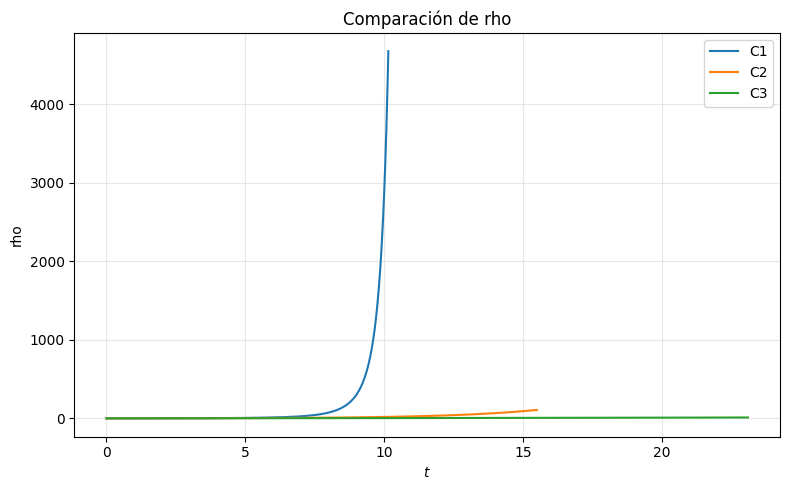

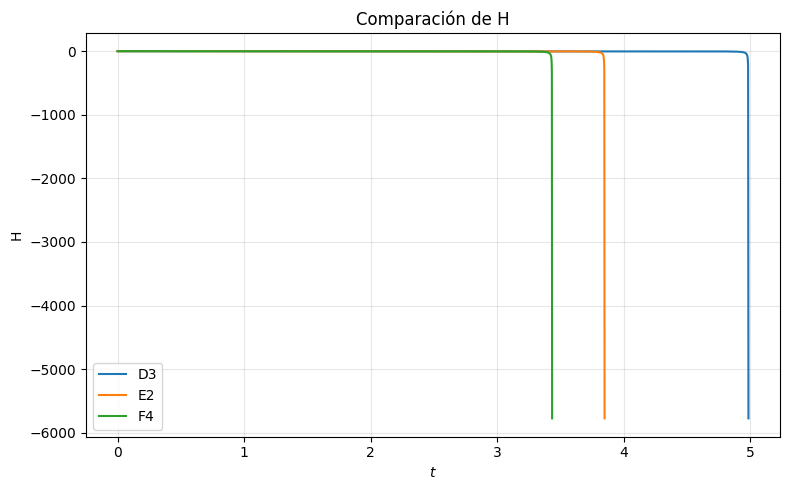

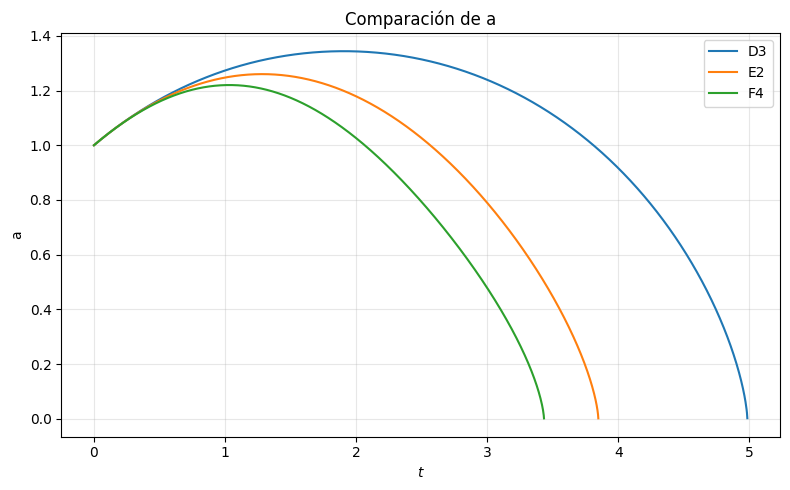

In [28]:
# Ejemplos de comportamientos cualitativamente distintos.
compare_cases(
    ["C1", "C2", "C3"],
    "rho",
)

compare_cases(
    ["D3", "E2", "F4"],
    "H",
    signed=True,
)

compare_cases(
    ["D3", "E2", "F4"],
    "a",
    signed=True,
)

## 17. Exportación opcional

Las tablas pueden guardarse en CSV para análisis posterior. La exportación está desactivada por defecto.

In [29]:
EXPORT_RESULTS = False

if EXPORT_RESULTS:
    output_directory = Path(
        "resultados_modelo_barotropico_difusion"
    )

    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    initial_case_table.to_csv(
        output_directory
        / "initial_case_table.csv",
        index=False,
    )

    direct_summary.to_csv(
        output_directory
        / "direct_summary.csv",
        index=False,
    )

    growth_convergence.to_csv(
        output_directory
        / "growth_convergence.csv",
        index=False,
    )

    decay_convergence.to_csv(
        output_directory
        / "decay_convergence.csv",
        index=False,
    )

    boundary_convergence.to_csv(
        output_directory
        / "boundary_convergence.csv",
        index=False,
    )

    signed_summary.to_csv(
        output_directory
        / "signed_summary.csv",
        index=False,
    )

    collapse_convergence.to_csv(
        output_directory
        / "collapse_convergence.csv",
        index=False,
    )

    classification_table.to_csv(
        output_directory
        / "classification_table.csv",
        index=False,
    )

    behavior_inventory.to_csv(
        output_directory
        / "behavior_inventory.csv",
        index=False,
    )

    print(
        "Resultados guardados en:",
        output_directory.resolve(),
    )

## 18. Control global de calidad

Este resumen comprueba la consistencia computacional del notebook. No exige que las soluciones pertenezcan a una categoría física predeterminada.

In [30]:
quality_control = {
    "beta_1_exact_solution": bool(
        beta_one_validation[
            "passes_1e-7"
        ].all()
    ),
    "general_equations": bool(
        general_validation[
            "passes"
        ].all()
    ),
    "event_detection": bool(
        event_validation[
            "passes"
        ].all()
    ),
    "signed_constraint": bool(
        signed_validation[
            "constraint_passes_1e-6"
        ]
    ),
    "no_direct_integration_errors": (
        len(direct_errors) == 0
    ),
    "no_signed_integration_errors": (
        len(signed_errors) == 0
    ),
    "all_cases_classified": bool(
        (
            classification_table[
                "observed_label"
            ]
            != "unclassified"
        ).all()
    ),
    "no_forced_expected_labels": True,
}

quality_control

{'beta_1_exact_solution': True,
 'general_equations': True,
 'event_detection': True,
 'signed_constraint': True,
 'no_direct_integration_errors': True,
 'no_signed_integration_errors': True,
 'all_cases_classified': True,
 'no_forced_expected_labels': True}

## 19. Conclusiones metodológicas

Este notebook distingue tres niveles:

1. **validación matemática del código**, mediante identidades exactas;
2. **observación numérica**, mediante integraciones, eventos y estudios de convergencia;
3. **interpretación física**, asignada solo cuando los diagnósticos son consistentes.

Las fronteras \(F=0\) no se consideran automáticamente singularidades. La integración con \(H\) signado permite observar que varias ramas atraviesan \(H=0\), alcanzan un máximo de \(a(t)\) y entran en contracción. En los casos estudiados, esa contracción puede conducir a:

- un Big Crunch en tiempo finito;
- una frontera \(D=0\) con divergencia de derivadas superiores.

Por otra parte, para \(\beta<0\), \(\alpha>0\), \(\omega<-1\) y una condición inicial situada bajo \(\rho_D\), aparece una rama en la que

\[
\rho\to0,
\qquad
\dot H\to0,
\qquad
H\to\infty,
\qquad
a\to\infty,
\qquad
t\to\infty.
\]

Esta rama queda registrada como **rip en tiempo infinito dominado por difusión**, sin forzarla a coincidir con una singularidad finita estándar.

La exploración extendida permite añadir nuevos estados iniciales alrededor de \(\beta=0,1,2\), \(\rho_H\) y \(\rho_D\). De esta forma, cualquier comportamiento que no coincida con las firmas actuales puede conservarse como no concluyente y estudiarse por separado.